In [6]:
import pandas as pd
from pathlib import Path

# ======================
# USER CONFIG
# ======================
DATA_PATH = Path("C:/Users/User/Jupyter projects/eeg-analysis/cog_bci/RSME.txt")   # .txt or .csv
EXPORT_MISSING = True            # save missing rows to file
FAIL_ON_ERROR = False            # hard-stop pipeline if issues exist

# Expected design
EXPECTED_SUBJECTS = set(range(1, 30))   # 1..29
EXPECTED_SESSIONS = {1, 2, 3}
EXPECTED_CONDITIONS = set(range(1, 9))  # 1..8

EXPECTED_ROWS = 29 * 3 * 8

# ======================
# LOAD DATA
# ======================
df = pd.read_csv(
    DATA_PATH,
    sep=None,        # auto-detect delimiter
    engine="python"
)

df.columns = [c.strip() for c in df.columns]

REQUIRED_COLUMNS = {"sbj", "Session", "Condition", "Score"}
missing_cols = REQUIRED_COLUMNS - set(df.columns)
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

# ======================
# CHECKS
# ======================
issues = []

# ---- 1. Row count ----
if len(df) != EXPECTED_ROWS:
    issues.append(f"Row count mismatch: {len(df)} vs expected {EXPECTED_ROWS}")

# ---- 2. Subjects ----
subjects_present = set(df["sbj"].unique())
missing_subjects = sorted(EXPECTED_SUBJECTS - subjects_present)
extra_subjects = sorted(subjects_present - EXPECTED_SUBJECTS)

# ---- 3. Missing sessions per subject ----
missing_sessions = []
for sbj in EXPECTED_SUBJECTS:
    sessions_present = set(df.loc[df["sbj"] == sbj, "Session"])
    for ses in EXPECTED_SESSIONS - sessions_present:
        missing_sessions.append({"sbj": sbj, "Session": ses})

missing_sessions_df = pd.DataFrame(missing_sessions)

# ---- 4. Full (sbj, session, condition) factorial check ----
expected_index = pd.MultiIndex.from_product(
    [EXPECTED_SUBJECTS, EXPECTED_SESSIONS, EXPECTED_CONDITIONS],
    names=["sbj", "Session", "Condition"]
)

actual_index = pd.MultiIndex.from_frame(
    df[["sbj", "Session", "Condition"]]
)

missing_combinations = expected_index.difference(actual_index)
missing_combinations_df = missing_combinations.to_frame(index=False)

# ---- 5. Missing scores ----
missing_scores_df = df[df["Score"].isna()]

# ---- 6. Duplicates ----
duplicates_df = df[
    df.duplicated(
        subset=["sbj", "Session", "Condition"],
        keep=False
    )
]

# ======================
# REPORT
# ======================
print("\n" + "=" * 60)
print("DATASET INTEGRITY CHECK (DETAILED)")
print("=" * 60)

print(f"File: {DATA_PATH}")
print(f"Rows: {len(df)} / {EXPECTED_ROWS}")

if missing_subjects:
    print(f"\n❌ Missing subjects ({len(missing_subjects)}):")
    print(missing_subjects)

if extra_subjects:
    print(f"\n⚠️ Unexpected subjects ({len(extra_subjects)}):")
    print(extra_subjects)

if not missing_sessions_df.empty:
    print(f"\n❌ Missing sessions ({len(missing_sessions_df)}):")
    print(missing_sessions_df.to_string(index=False))

if not missing_combinations_df.empty:
    print(f"\n❌ Missing (sbj, session, condition) rows ({len(missing_combinations_df)}):")
    print(missing_combinations_df.to_string(index=False))

if not missing_scores_df.empty:
    print(f"\n❌ Rows with missing Score ({len(missing_scores_df)}):")
    print(missing_scores_df.to_string(index=False))

if not duplicates_df.empty:
    print(f"\n❌ Duplicate rows ({len(duplicates_df)}):")
    print(duplicates_df.sort_values(["sbj", "Session", "Condition"]).to_string(index=False))

if not any([
    missing_subjects,
    extra_subjects,
    not missing_sessions_df.empty,
    not missing_combinations_df.empty,
    not missing_scores_df.empty,
    not duplicates_df.empty
]):
    print("\n✅ DATASET IS COMPLETE AND CONSISTENT")

print("=" * 60)

# ======================
# EXPORT (OPTIONAL)
# ======================
if EXPORT_MISSING:
    if not missing_combinations_df.empty:
        missing_combinations_df.to_csv(
            "missing_subject_session_condition.csv",
            index=False
        )
    if not missing_sessions_df.empty:
        missing_sessions_df.to_csv(
            "missing_subject_session.csv",
            index=False
        )
    if not missing_scores_df.empty:
        missing_scores_df.to_csv(
            "rows_with_missing_scores.csv",
            index=False
        )
    if not duplicates_df.empty:
        duplicates_df.to_csv(
            "duplicate_rows.csv",
            index=False
        )

# ======================
# HARD FAIL OPTION
# ======================
if FAIL_ON_ERROR and any([
    missing_subjects,
    extra_subjects,
    not missing_sessions_df.empty,
    not missing_combinations_df.empty,
    not missing_scores_df.empty,
    not duplicates_df.empty
]):
    raise RuntimeError("Dataset integrity check failed")


DATASET INTEGRITY CHECK (DETAILED)
File: C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\RSME.txt
Rows: 685 / 696

❌ Missing sessions (1):
 sbj  Session
  14        3

❌ Missing (sbj, session, condition) rows (11):
 sbj  Session  Condition
  14        3          1
  14        3          2
  14        3          3
  14        3          4
  14        3          5
  14        3          6
  14        3          7
  14        3          8
  16        2          7
  16        3          4
  19        1          2


In [1]:
# Cell 1: imports, paths, load fold JSONs and results_per_fold
import os, glob, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import confusion_matrix, balanced_accuracy_score, precision_recall_fscore_support
import joblib
import warnings
warnings.filterwarnings("ignore")

# ---------------- CONFIG (edit paths if needed) ----------------
OUT_DIR = Path("C:/Users/User/Jupyter projects/eeg-analysis/cog_bci/features/loso_results/label_3class/2025-12-28_05-59-04")
CSV_PATH = Path("C:/Users/User/Jupyter projects/eeg-analysis/cog_bci/features/features_final_prepared.csv")
SAVE_DIR = OUT_DIR / "analysis"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# constants
RANDOM_STATE = 42
N_BOOT = 1000
ALPHA = 0.05

# ---------------- Load fold JSONs and results per fold ----------------
fold_files = sorted(glob.glob(str(OUT_DIR / "fold_*_summary.json")))
folds = [json.load(open(f)) for f in fold_files]
print(f"Loaded {len(folds)} fold JSON files")

# load results_per_fold if exists, else build from folds
results_csv = SAVE_DIR / "results_per_fold.csv"
if results_csv.exists():
    df_folds = pd.read_csv(results_csv)
else:
    rows = []
    for j in folds:
        fold = int(j['test_subject'])
        for mname, m in j.get('models', {}).items():
            rows.append({
                'fold': fold,
                'model': mname,
                'n_train_rows': j['n_train_rows'],
                'n_test_rows': j['n_test_rows'],
                'balacc_epoch': m.get('test_balanced_accuracy_epoch', np.nan),
                'acc_epoch': m.get('test_accuracy_epoch', np.nan),
                'f1_epoch': m.get('test_f1_epoch', np.nan),
                'auc_epoch': m.get('test_auc_epoch', np.nan),
                'balacc_task': m.get('test_balanced_accuracy_task', np.nan),
                'acc_task': m.get('test_accuracy_task', np.nan),
                'f1_task': m.get('test_f1_task', np.nan),
                'auc_task': m.get('test_auc_task', np.nan),
                'n_tasks_test': m.get('n_tasks_test', np.nan),
            })
    df_folds = pd.DataFrame(rows)
    df_folds = df_folds.sort_values(by='fold', ascending=True)
    df_folds.to_csv(results_csv, index=False)

# quick checks
print("models found:", df_folds['model'].unique())
print("folds count:", df_folds['fold'].nunique())

Loaded 29 fold JSON files
models found: ['XGB' 'TangentLR' 'RF' 'MDM']
folds count: 29


In [29]:
df_folds

,fold,model,n_train_rows,n_test_rows,balacc_epoch,acc_epoch,f1_epoch,auc_epoch,balacc_task,acc_task,f1_task,auc_task,n_tasks_test
40,1,XGB,31544,1193,0.388378,0.388935,0.344278,0.604666,0.388889,0.388889,0.311111,0.708333,18
43,1,TangentLR,31544,1193,0.336295,0.336966,0.321056,0.570909,0.333333,0.333333,0.234848,0.652778,18
41,1,RF,31544,1193,0.345395,0.345348,0.273037,0.573195,0.222222,0.222222,0.133333,0.597222,18
42,1,MDM,31544,1193,0.343961,0.344510,0.274850,NaN,0.333333,0.333333,0.271493,NaN,18
84,2,XGB,31583,1154,0.487385,0.487868,0.481917,0.675349,0.611111,0.611111,0.598906,0.791667,18
...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,28,TangentLR,31610,1127,0.314216,0.315883,0.280537,0.506496,0.333333,0.333333,0.269360,0.490741,18
80,29,XGB,31629,1108,0.365934,0.366426,0.350225,0.562437,0.277778,0.277778,0.203704,0.615741,18
81,29,RF,31629,1108,0.381465,0.381769,0.380136,0.596849,0.277778,0.277778,0.235897,0.606481,18
83,29,TangentLR,31629,1108,0.353711,0.353791,0.333921,0.564111,0.388889,0.388889,0.300000,0.574074,18


In [5]:
# Cell 2: Table 1 generation (mean ± 95% CI for balanced accuracy + secondary metrics)
def bootstrap_ci_mean(x, n_boot=N_BOOT, seed=RANDOM_STATE):
    x = np.array(x.dropna()) if isinstance(x, pd.Series) else np.array(x)
    rng = np.random.RandomState(seed)
    boots = np.empty(n_boot)
    n = len(x)
    if n == 0:
        return np.nan, np.nan, np.nan
    for i in range(n_boot):
        sample = rng.choice(x, size=n, replace=True)
        boots[i] = sample.mean()
    return x.mean(), np.percentile(boots, 2.5), np.percentile(boots, 97.5)

models = sorted(df_folds['model'].unique())
rows = []
for m in models:
    g = df_folds[df_folds['model']==m]
    mean, low, high = bootstrap_ci_mean(g['balacc_epoch'])
    rows.append({
        'model': m,
        'mean_balacc_epoch': mean,
        'balacc_95ci_low': low,
        'balacc_95ci_high': high,
        'mean_f1_epoch': g['f1_epoch'].mean(),
        'std_f1_epoch': g['f1_epoch'].std(),
        'mean_acc_epoch': g['acc_epoch'].mean(),
        'std_acc_epoch': g['acc_epoch'].std(),
        'mean_auc_epoch': g['auc_epoch'].mean(),
        'n_folds': int(g['fold'].nunique())
    })
table1 = pd.DataFrame(rows).sort_values('mean_balacc_epoch', ascending=False).reset_index(drop=True)
table1.to_csv(SAVE_DIR / "table1_model_performance_CI_bootstrap.csv", index=False)
table1

,model,mean_balacc_epoch,balacc_95ci_low,balacc_95ci_high,mean_f1_epoch,std_f1_epoch,mean_acc_epoch,std_acc_epoch,mean_auc_epoch,n_folds
0,XGB,0.448800,0.400495,0.511116,0.432818,0.160077,0.448935,0.154431,0.636182,29
1,RF,0.417600,0.399666,0.438799,0.381011,0.068498,0.417244,0.056751,0.622342,29
2,TangentLR,0.409577,0.390861,0.430329,0.377155,0.069295,0.409385,0.053379,0.600838,29
3,MDM,0.380039,0.361763,0.397776,0.311955,0.078323,0.379992,0.049745,NaN,29


In [6]:
# Cell 3: Friedman omnibus and pairwise Wilcoxon with FDR and Cohen's d (paired)
from scipy.stats import friedmanchisquare, wilcoxon

# pivot to shape (fold x model) for primary metric
pivot = df_folds.pivot(index='fold', columns='model', values='balacc_epoch').dropna()
models = pivot.columns.tolist()

# Friedman omnibus
friedman_stat, friedman_p = friedmanchisquare(*(pivot[m].values for m in models))
print("Friedman:", friedman_stat, friedman_p)

# Pairwise Wilcoxon and effect sizes (Cohen's d for paired)
pairs = []
pvals = []
dvals = []
for i in range(len(models)):
    for j in range(i+1, len(models)):
        a = pivot[models[i]].values
        b = pivot[models[j]].values
        try:
            stat, p = wilcoxon(a, b)
        except Exception as e:
            # if wilcoxon fails (e.g., zero differences), fallback to t-test
            tstat, p = stats.ttest_rel(a, b, nan_policy='omit')
            stat = tstat
        diff = a - b
        # paired Cohen's d:
        d = diff.mean() / (diff.std(ddof=1) if diff.std(ddof=1) > 0 else np.nan)
        pairs.append(f"{models[i]} vs {models[j]}")
        pvals.append(p)
        dvals.append(d)

# FDR correction
reject, pvals_fdr, _, _ = multipletests(pvals, alpha=ALPHA, method='fdr_bh')
comp_df = pd.DataFrame({'pair': pairs, 'p_uncorrected': pvals, 'p_fdr': pvals_fdr, 'reject_fdr': reject, 'cohens_d': dvals})
comp_df.to_csv(SAVE_DIR / "table2_pairwise_Wilcoxon_comparisons.csv", index=False)
print("Friedman omnibus:", friedman_stat, friedman_p)
comp_df

Friedman: 12.641379310344803 0.005479961759808233
Friedman omnibus: 12.641379310344803 0.005479961759808233


,pair,p_uncorrected,p_fdr,reject_fdr,cohens_d
0,MDM vs RF,0.001399,0.008392,True,-0.663726
1,MDM vs TangentLR,0.021553,0.043106,True,-0.502414
2,MDM vs XGB,0.002992,0.008977,True,-0.502870
3,RF vs TangentLR,0.701329,0.701329,False,0.141464
4,RF vs XGB,0.494650,0.593580,False,-0.273594
5,TangentLR vs XGB,0.294118,0.441177,False,-0.299429


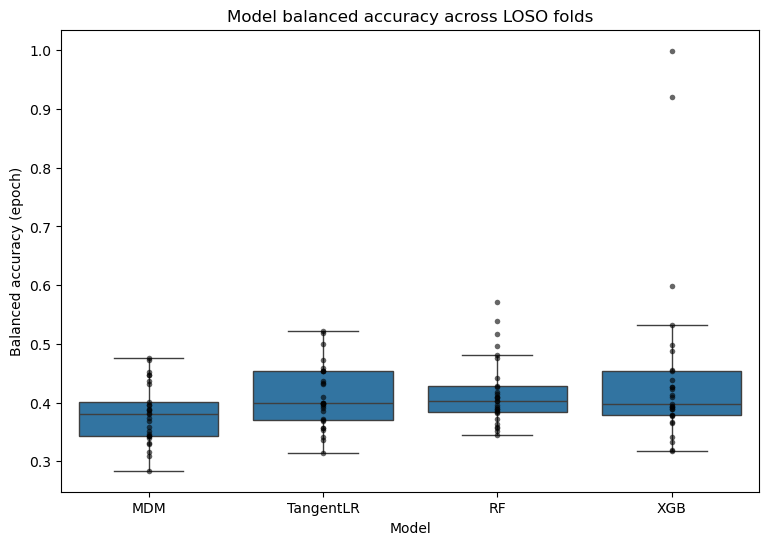

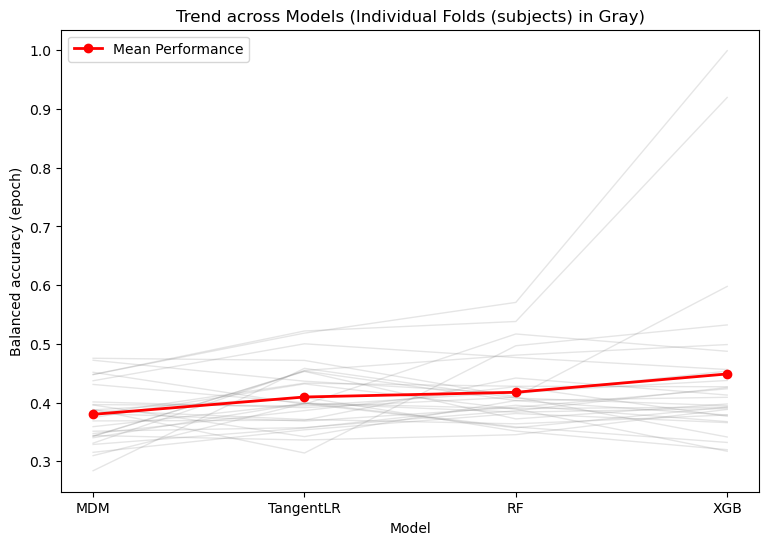

In [7]:
# # Cell 4: Figure 1 - boxplots + paired lines
model_order = ['MDM', 'TangentLR', 'RF', 'XGB']

# Pivot and then reorder the columns
pivot = df_folds.pivot(index='fold', columns='model', values='balacc_epoch').dropna()
pivot = pivot.reindex(columns=model_order)

plt.figure(figsize=(9,6))
sns.boxplot(x='model', y='balacc_epoch', data=df_folds, showfliers=False, order=model_order)
sns.stripplot(x='model', y='balacc_epoch', data=df_folds, color='k', size=4, jitter=False, alpha=0.6, order=model_order)
plt.ylabel("Balanced accuracy (epoch)")
plt.xlabel("Model")
plt.title("Model balanced accuracy across LOSO folds")
plt.savefig(SAVE_DIR / "fig1_box_balacc_epoch.png", dpi=150, bbox_inches='tight')
plt.show()

plt.figure(figsize=(9,6))
for idx, row in pivot.iterrows():
    plt.plot(range(len(pivot.columns)), row.values, '-', color='gray', alpha=0.2, linewidth=1)
mean_vals = pivot.mean()
plt.plot(range(len(pivot.columns)), mean_vals, '-o', color='red', 
         linewidth=2, markersize=6, label='Mean Performance')
plt.xticks(range(len(pivot.columns)), pivot.columns)
plt.ylabel("Balanced accuracy (epoch)")
plt.xlabel("Model")
plt.legend()
plt.title("Trend across Models (Individual Folds (subjects) in Gray)")
plt.savefig(SAVE_DIR / "fig1_per_subject_spaghetti.png", dpi=150, bbox_inches='tight')
plt.show()

Best model: XGB


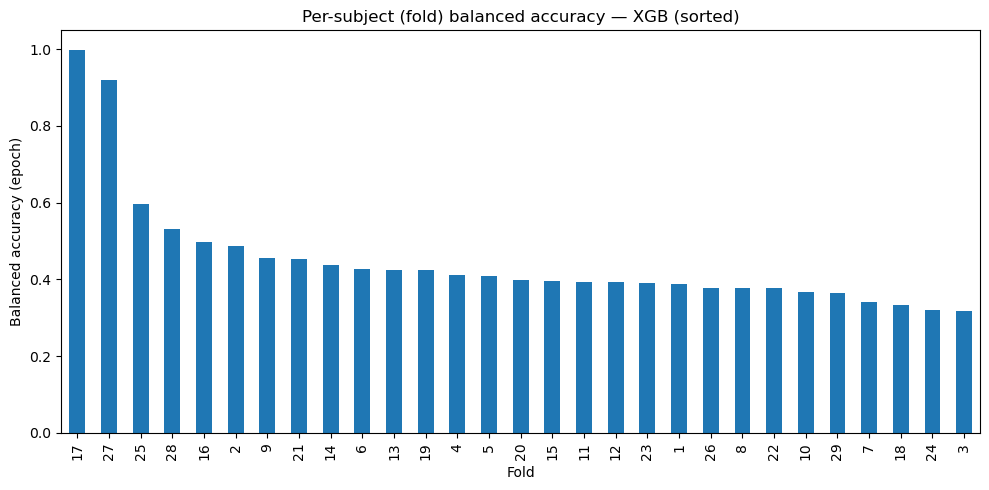

Best 5 subjects:
 |   fold |   balacc |
|-------:|---------:|
|     17 | 0.999097 |
|     27 | 0.919551 |
|     25 | 0.597818 |
|     28 | 0.532262 |
|     16 | 0.498827 |
Worst 5 subjects:
 |   fold |   balacc |
|-------:|---------:|
|     29 | 0.365934 |
|      7 | 0.341454 |
|     18 | 0.33219  |
|     24 | 0.31986  |
|      3 | 0.317206 |


In [8]:
# Cell 5: Per-subject bars for best model and table of best/worst subjects per model
# choose best model by mean in table1
best_model = table1.loc[0,'model']
print("Best model:", best_model)

pivot_best = df_folds[df_folds['model']==best_model].set_index('fold')['balacc_epoch']
sorted_pivot = pivot_best.sort_values(ascending=False)
plt.figure(figsize=(10,5))
sorted_pivot.plot(kind='bar')
plt.ylabel("Balanced accuracy (epoch)")
plt.xlabel("Fold")
plt.title(f"Per-subject (fold) balanced accuracy — {best_model} (sorted)")
plt.tight_layout()
plt.savefig(SAVE_DIR / f"fig2_per_subject_{best_model}.png", dpi=200)
plt.show()

# best/worst 5
best5 = sorted_pivot.head(5).reset_index().rename(columns={'balacc_epoch':'balacc'})
worst5 = sorted_pivot.tail(5).reset_index().rename(columns={'balacc_epoch':'balacc'})
best5.to_csv(SAVE_DIR / f"{best_model}_best5_subjects.csv", index=False)
worst5.to_csv(SAVE_DIR / f"{best_model}_worst5_subjects.csv", index=False)
print("Best 5 subjects:\n", best5.to_markdown(index=False))
print("Worst 5 subjects:\n", worst5.to_markdown(index=False))

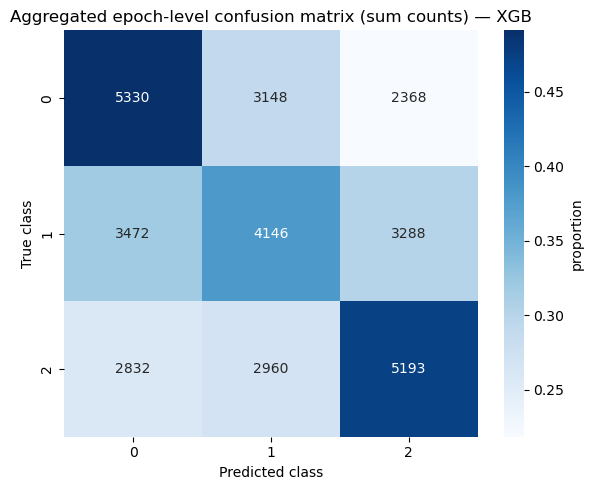

|   class |   precision |   recall |       f1 |
|--------:|------------:|---------:|---------:|
|       0 |    0.45814  | 0.491425 | 0.474199 |
|       1 |    0.40433  | 0.380158 | 0.391871 |
|       2 |    0.478662 | 0.472736 | 0.47568  |


In [9]:
# Cell 6: Confusion matrices aggregated across folds for the chosen model
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay

def aggregate_confusion(model_name, level='epoch'):
    # level: 'epoch' uses 'confusion_matrix_epoch' saved in JSONs; 'task' uses 'confusion_matrix_task'
    cm_sum = None
    for j in folds:
        m = j.get('models', {}).get(model_name, {})
        key = 'confusion_matrix_epoch' if level=='epoch' else 'confusion_matrix_task'
        cm = m.get(key, None)
        if cm is None:
            continue
        cm = np.array(cm)
        if cm_sum is None:
            cm_sum = cm.copy()
        else:
            cm_sum = cm_sum + cm
    return cm_sum

# epoch-level aggregated CM
cm_epoch = aggregate_confusion(best_model, level='epoch')
if cm_epoch is None:
    print("No epoch-level confusion matrices found for", best_model)
else:
    # normalize rows (true class)
    cm_norm = cm_epoch.astype(float) / cm_epoch.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(6,5))
    sns.heatmap(cm_norm, annot=cm_epoch.astype(int), fmt='d', cmap='Blues', ax=ax, cbar_kws={'label':'proportion'})
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('True class')
    ax.set_title(f'Aggregated epoch-level confusion matrix (sum counts) — {best_model}')
    plt.tight_layout()
    plt.savefig(SAVE_DIR / f"fig3_confusion_epoch_{best_model}.png", dpi=200)
    plt.show()

# per-class precision/recall/f1 (from aggregated counts)
if cm_epoch is not None:
    tp = np.diag(cm_epoch).astype(float)
    recall = tp / cm_epoch.sum(axis=1)
    precision = tp / cm_epoch.sum(axis=0)
    f1 = 2 * (precision * recall) / (precision + recall)
    per_class = pd.DataFrame({'class': range(len(tp)), 'precision': precision, 'recall': recall, 'f1': f1})
    per_class.to_csv(SAVE_DIR / f"{best_model}_per_class_metrics.csv", index=False)
    print(per_class.to_markdown(index=False))

Task-level rows: 2088


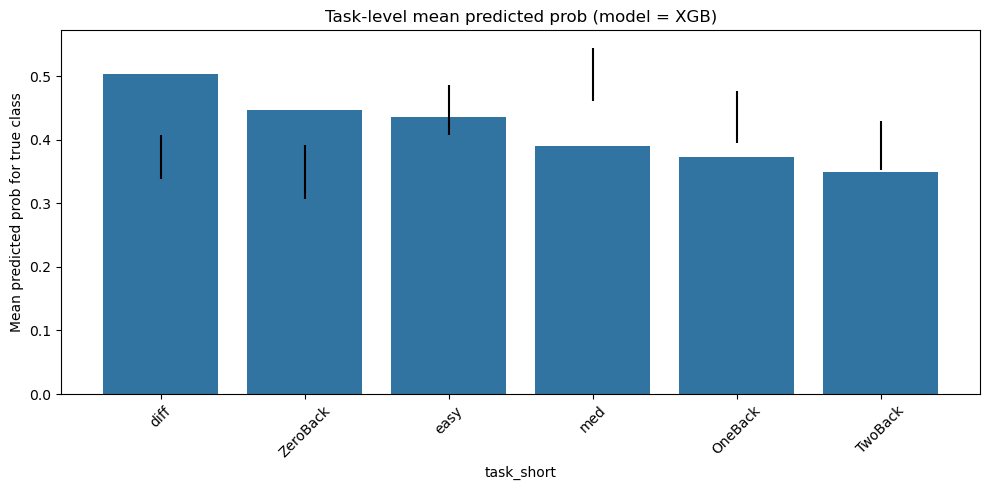

         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: prob_true
No. Observations: 522     Method:             ML       
No. Groups:       29      Scale:              0.0269   
Min. group size:  18      Log-Likelihood:     172.5514 
Max. group size:  18      Converged:          Yes      
Mean group size:  18.0                                 
-------------------------------------------------------
             Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept     0.424    0.022 19.030 0.000  0.380  0.467
true         -0.008    0.009 -0.857 0.391 -0.025  0.010
Group Var     0.011    0.020                           



In [10]:
# Cell 7: Build task-level dataframe across folds and test trend / mixed model
import statsmodels.formula.api as smf

task_rows = []
for j in folds:
    fold = int(j['test_subject'])
    for mname, m in j.get('models', {}).items():
        tlev = m.get('task_level_summary', {})
        for tid, info in (tlev.items() if isinstance(tlev, dict) else []):
            true = info.get('true', np.nan)
            pred = info.get('pred', np.nan)
            # ensure prob vector exists and fetch probability for true class
            prob = np.nan
            if info.get('prob') is not None and isinstance(info['prob'], (list, tuple)):
                try:
                    prob = float(info['prob'][int(true)])
                except Exception:
                    prob = np.nan
            task_rows.append({'fold': fold, 'model': mname, 'task_id': tid, 'true': int(true) if not np.isnan(true) else np.nan, 'pred': int(pred) if not np.isnan(pred) else np.nan, 'prob_true': prob})
task_df = pd.DataFrame(task_rows).dropna(subset=['prob_true'])
task_df.to_csv(SAVE_DIR / "task_level_summary_all_v2_same.csv", index=False)
print("Task-level rows:", len(task_df))

# plot mean prob_true by task id or by grouped task type if tidy names
# try to extract a short task label (e.g., OneBack / TwoBack / MATB_easy)
task_df['task_short'] = task_df['task_id'].apply(lambda x: str(x).split('_')[-2] if isinstance(x, str) and '_' in x else x)
agg = task_df[task_df['model']==best_model].groupby('task_short')['prob_true'].agg(['mean','count','std']).reset_index()
agg['ci_low'] = agg['mean'] - 1.96 * agg['std'] / np.sqrt(agg['count'])
agg['ci_high'] = agg['mean'] + 1.96 * agg['std'] / np.sqrt(agg['count'])
plt.figure(figsize=(10,5))
sns.barplot(x='task_short', y='mean', data=agg, order=agg.sort_values('mean', ascending=False)['task_short'])
plt.errorbar(x=np.arange(len(agg)), y=agg['mean'], yerr=[agg['mean']-agg['ci_low'], agg['ci_high']-agg['mean']], fmt='none', color='k')
plt.ylabel('Mean predicted prob for true class')
plt.title(f'Task-level mean predicted prob (model = {best_model})')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(SAVE_DIR / f"fig4_v2_same_task_probs_{best_model}.png", dpi=200)
plt.show()

# Mixed-effects: prob_true ~ true (treat true as numeric ordered) with random intercept per fold
try:
    md = smf.mixedlm("prob_true ~ true", task_df[task_df['model']==best_model], groups=task_df[task_df['model']==best_model]["fold"])
    mres = md.fit(reml=False)
    print(mres.summary())
    with open(SAVE_DIR / f"mixed_model_v2_same_{best_model}.txt", "w") as f:
        f.write(mres.summary().as_text())
except Exception as e:
    print("Mixed model failed:", e)

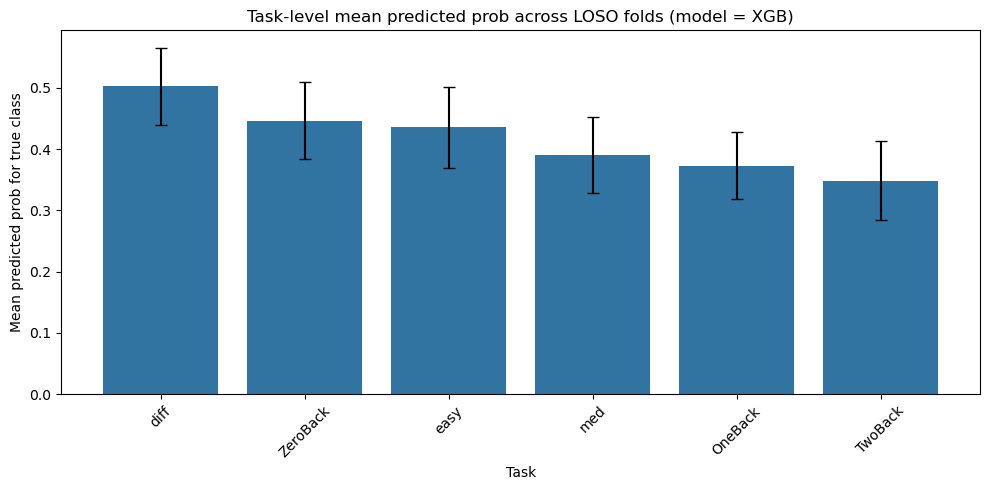

In [11]:
df_best = task_df[task_df['model'] == best_model].copy()

fold_task = (
    df_best
    .groupby(['fold', 'task_short'])['prob_true']
    .mean()
    .reset_index()
)

agg = (
    fold_task
    .groupby('task_short')['prob_true']
    .agg(['mean', 'count', 'std'])
    .reset_index()
)

agg['sem'] = agg['std'] / np.sqrt(agg['count'])

# t-based CI, better for small n
agg['tcrit'] = agg['count'].apply(lambda n: stats.t.ppf(0.975, df=n-1) if n > 1 else np.nan)
agg['ci_low'] = agg['mean'] - agg['tcrit'] * agg['sem']
agg['ci_high'] = agg['mean'] + agg['tcrit'] * agg['sem']

agg_plot = agg.sort_values('mean', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 5))

sns.barplot(
    x='task_short',
    y='mean',
    data=agg_plot,
    order=agg_plot['task_short']
)

plt.errorbar(
    x=np.arange(len(agg_plot)),
    y=agg_plot['mean'],
    yerr=[
        agg_plot['mean'] - agg_plot['ci_low'],
        agg_plot['ci_high'] - agg_plot['mean']
    ],
    fmt='none',
    color='k',
    capsize=4
)

plt.ylabel('Mean predicted prob for true class')
plt.xlabel('Task')
plt.title(f'Task-level mean predicted prob across LOSO folds (model = {best_model})')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(SAVE_DIR / f"fig4_v2_task_probs_{best_model}_fold_ci.png", dpi=200)
plt.show()

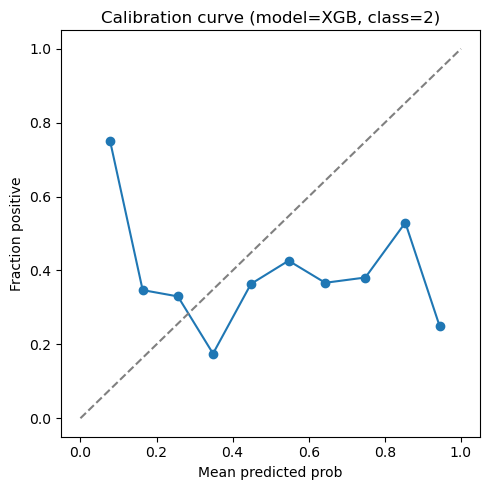

In [58]:
# Cell 8: Brier score + calibration per major class (example uses class=2 as target)
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

calib_rows = []
for m in models:
    g = task_df[task_df['model']==m].copy()
    if g.empty:
        continue
    # compute brier for true class prob (averaged)
    brier = np.mean((1.0 - g['prob_true'])**2)
    calib_rows.append({'model': m, 'brier_task': brier})
pd.DataFrame(calib_rows).to_csv(SAVE_DIR / "brier_task_by_model.csv", index=False)

# calibration curve for best_model class 2 vs rest (example)
g = task_df[task_df['model']==best_model].copy()
if not g.empty:
    # binary for one class (choose class with idx 2 as example)
    y_true = (g['true'] == 2).astype(int)
    y_prob = g['prob_true']  # note: prob_true is prob of the true class; for calibration per class you'd extract per-class probs
    frac_pos, mean_pred = calibration_curve(y_true, y_prob, n_bins=10)
    plt.figure(figsize=(5,5))
    plt.plot(mean_pred, frac_pos, marker='o')
    plt.plot([0,1],[0,1],'--', color='gray')
    plt.xlabel('Mean predicted prob')
    plt.ylabel('Fraction positive')
    plt.title(f'Calibration curve (model={best_model}, class=2)')
    plt.tight_layout()
    plt.savefig(SAVE_DIR / f"fig5_calibration_{best_model}_class2.png", dpi=200)
    plt.show()

In [4]:
"""
shap_loso_top_features_fixed.py

Updated script: robust SHAP handling and fixes for mismatched shapes and n_classes detection.

Edit CONFIG below before running.
"""

import os
import glob
import json
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import shap
from scipy import stats

# --------------- CONFIG ---------------
OUT_DIR = Path(r"C:/Users/User/Jupyter projects/eeg-analysis/cog_bci/features/loso_results/label_3class/2025-12-28_05-59-04")
CSV_PATH = Path(r"C:/Users/User/Jupyter projects/eeg-analysis/cog_bci/features/features_final_prepared.csv")
MODEL_NAME = "XGB"
ID_COLS = ["subject", "subject_num", "session", "session_num", "task", "epoch_idx", "source_file",
           "label_3class", "label_binary", "rsme_score", "pc_dist", "is_outlier"]
SAVE_DIR = OUT_DIR / "analysis_shap_fixed"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TOP_K = 30
BOOTSTRAP_N = 1000
BG_MAX = 200  # background samples for shap explainer
# --------------------------------------

def get_pipeline_and_parts(mdl):
    """
    Given a loaded joblib object, return (pipeline_transformer, classifier)
    transformer: pipeline without final estimator (or None)
    classifier: final estimator object
    """
    # If hyperparameter search wrapper
    if hasattr(mdl, 'best_estimator_'):
        pipe = mdl.best_estimator_
    else:
        pipe = mdl

    # If it's a Pipeline with named_steps
    from sklearn.pipeline import Pipeline
    if isinstance(pipe, Pipeline):
        steps = list(pipe.named_steps.items())
        if len(steps) == 0:
            return None, pipe
        # classifier = last step
        clf = pipe
        last_name, last_est = steps[-1]
        # transformer = pipeline made of all but last
        if len(steps) > 1:
            transformer = Pipeline(steps[:-1])
        else:
            transformer = None
        # classifier object is the last estimator
        classifier = last_est
        return transformer, classifier
    else:
        # not a pipeline, treat entire object as classifier
        return None, pipe

def find_selected_feature_names(transformer, feat_cols):
    """
    Try to find feature selector inside transformer (SelectKBest or similar)
    and map it back to feat_cols. If not found, return None.
    """
    if transformer is None:
        return None
    # If transformer has named_steps (it is a Pipeline)
    if hasattr(transformer, 'named_steps'):
        for name, step in transformer.named_steps.items():
            if hasattr(step, "get_support"):
                try:
                    mask = step.get_support()
                    # if mask is boolean of length len(feat_cols)
                    if len(mask) == len(feat_cols):
                        return [feat_cols[i] for i, m in enumerate(mask) if m]
                    # otherwise ignore
                except Exception:
                    continue
    else:
        # single transformer object
        step = transformer
        if hasattr(step, "get_support"):
            try:
                mask = step.get_support()
                if len(mask) == len(feat_cols):
                    return [feat_cols[i] for i, m in enumerate(mask) if m]
            except Exception:
                pass
    return None

def standardize_shap_values(shap_values, X_trans, selected_feature_names):
    """
    Normalize various shap outputs to shape (n_classes, n_samples, n_features).
    Returns (shap_arr_abs, error_msg). shap_arr_abs contains absolute values.
    If shap_arr_abs is None, error_msg explains why fold should be skipped.
    """
    # list -> stack (common for multiclass tree explainer)
    if isinstance(shap_values, list):
        try:
            arrs = [np.abs(np.asarray(s)) for s in shap_values]
            shap_arr = np.stack(arrs, axis=0)  # (n_classes, n_samples, n_features)
            if shap_arr.ndim != 3:
                return None, f"stacked list produced unexpected shape {shap_arr.shape}"
            return shap_arr, None
        except Exception as e:
            return None, f"stacking list shap_values failed: {e}"

    arr = np.abs(np.asarray(shap_values))
    # quick diagnostic print (optional) - helps debug unexpected shapes
    # print("DEBUG: raw shap array shape:", arr.shape, "test X shape:", X_trans.shape)

    # Case: (n_samples, n_features) -> single-output model
    if arr.ndim == 2 and arr.shape[1] == X_trans.shape[1]:
        return arr[np.newaxis, :, :], None

    # Case: (n_samples, n_classes, n_features) -> transpose to (n_classes, n_samples, n_features)
    if arr.ndim == 3:
        # common possibilities:
        # (n_samples, n_classes, n_features)
        if arr.shape[0] == X_trans.shape[0] and arr.shape[2] == X_trans.shape[1]:
            return np.transpose(arr, (1, 0, 2)), None
        # (n_samples, n_features, n_classes)  <- your case (1123,60,3)
        if arr.shape[0] == X_trans.shape[0] and arr.shape[1] == X_trans.shape[1] and arr.shape[2] != X_trans.shape[1]:
            # convert (n_samples, n_features, n_classes) -> (n_classes, n_samples, n_features)
            return np.transpose(arr, (2, 0, 1)), None
        # already (n_classes, n_samples, n_features)
        if arr.shape[1] == X_trans.shape[0] and arr.shape[2] == X_trans.shape[1]:
            return arr, None
        return None, f"3D shap array {arr.shape} doesn't match test data shape {X_trans.shape}"

    # 2D arrays that lack feature axis (e.g., (n_samples, n_classes) or (n_samples,)) cannot be mapped to features
    if arr.ndim == 2:
        return None, ("SHAP returned 2D array without a feature axis (likely per-sample-per-class "
                      "aggregated values). Cannot map to feature names.")

    return None, f"Unhandled SHAP output shape: {arr.shape}"


def compute_shap_for_classifier(clf, X_test_trans):
    """
    Compute SHAP values using TreeExplainer for an XGBoost classifier.

    Handles XGBoost 3.x multiclass base_score issue where the config
    stores base_score as a vector string that SHAP cannot parse.
    """

    import json
    import numpy as np
    import shap

    X_test_trans = np.asarray(X_test_trans)

    if not hasattr(clf, "get_booster"):
        return None, "Classifier does not expose get_booster(); not an XGBoost model."

    try:
        booster = clf.get_booster()
    except Exception as e:
        return None, f"Could not extract booster: {e}"

    # ---- Patch XGBoost multiclass base_score bug ----
    try:
        cfg = json.loads(booster.save_config())

        base = cfg["learner"]["learner_model_param"].get("base_score", None)

        if isinstance(base, str) and "[" in base:
            # SHAP expects scalar base_score; replace vector with neutral scalar
            cfg["learner"]["learner_model_param"]["base_score"] = "0.5"
            booster.load_config(json.dumps(cfg))

    except Exception as e:
        print("  WARNING: base_score patch failed:", e)
    # -------------------------------------------------

    try:
        explainer = shap.TreeExplainer(
            booster,
            feature_perturbation="tree_path_dependent",
            model_output="raw"
        )

        shap_values = explainer.shap_values(X_test_trans)

        return shap_values, None

    except Exception as e:
        return None, f"TreeExplainer failed: {e}"


# ---------------- load folds and features ----------------
fold_json_files = sorted(glob.glob(str(OUT_DIR / "fold_*_summary.json")))
if len(fold_json_files) == 0:
    raise FileNotFoundError(f"No fold summary JSONs found in {OUT_DIR}")

df = pd.read_csv(CSV_PATH)
if "subject_num" not in df.columns:
    raise KeyError("subject_num not found in features CSV. Adjust CSV_PATH or ID_COLS.")

feat_cols = [c for c in df.columns if c not in ID_COLS and c not in ("label_3class", "label_binary", "rsme_score")]
print(f"Detected {len(feat_cols)} candidate features.")

fold_importances = {}   # feat_name -> list of arrays (n_classes,)
fold_records = []

for jf in fold_json_files:
    j = json.load(open(jf))
    # determine test subject
    test_subject = j.get("test_subject", None)
    if test_subject is None:
        # fallback parse from filename
        basename = Path(jf).stem
        parts = basename.split("_")
        try:
            test_subject = int(parts[1])
        except Exception:
            print(f"Cannot determine test subject for {jf}; skipping.")
            fold_records.append({'fold': basename, 'status': 'no_test_subject'})
            continue
    test_subject = int(test_subject)
    print(f"\nProcessing fold {test_subject} ({jf})")

    # load joblib model
    model_candidates = glob.glob(str(OUT_DIR / f"fold_{test_subject}*{MODEL_NAME}*.joblib"))
    if len(model_candidates) == 0:
        print(f"  WARNING: no joblib model found for fold {test_subject} model {MODEL_NAME}. Skipping.")
        fold_records.append({'fold': test_subject, 'status': 'no_joblib'})
        continue
    model_path = Path(model_candidates[0])
    print(f"  Loading model from: {model_path}")
    mdl = joblib.load(model_path)

    transformer, clf = get_pipeline_and_parts(mdl)

    # select test rows
    test_mask = (pd.to_numeric(df['subject_num'], errors='coerce') == test_subject)
    X_test_df = df.loc[test_mask, feat_cols].copy()
    if X_test_df.shape[0] == 0:
        print(f"  WARNING: no rows found for subject {test_subject} in features CSV. Skipping fold.")
        fold_records.append({'fold': test_subject, 'status': 'no_test_rows'})
        continue

    # attempt transform with transformer (if present)
    try:
        if transformer is not None:
            try:
                X_test_trans = transformer.transform(X_test_df.values)
            except Exception:
                X_test_trans = transformer.transform(X_test_df)
        else:
            X_test_trans = X_test_df.values
    except Exception as e:
        print(f"  ERROR: transformer.transform failed for fold {test_subject}: {e}")
        fold_records.append({'fold': test_subject, 'status': 'transform_fail', 'error': str(e)})
        continue

    # selected feature names for this fold (if SelectKBest used)
    sel_names = find_selected_feature_names(transformer, feat_cols)
    if sel_names is None:
        # assume all features if dims match
        if X_test_trans.ndim == 2 and X_test_trans.shape[1] == len(feat_cols):
            sel_names = feat_cols
        else:
            # fallback: create placeholder names
            sel_names = [f"f{i}" for i in range(X_test_trans.shape[1])]

    # Build background sample from training rows (subject != test_subject)
    bg_mask = (pd.to_numeric(df['subject_num'], errors='coerce') != test_subject)
    X_bg_df = df.loc[bg_mask, feat_cols]
    if X_bg_df.shape[0] == 0:
        bg_trans = None
    else:
        # sample up to BG_MAX rows for background
        try:
            if X_bg_df.shape[0] > BG_MAX:
                sample_idx = np.random.RandomState(RANDOM_STATE).choice(X_bg_df.index, size=BG_MAX, replace=False)
                X_bg_df = X_bg_df.loc[sample_idx]
            if transformer is not None:
                try:
                    bg_trans = transformer.transform(X_bg_df.values)
                except Exception:
                    bg_trans = transformer.transform(X_bg_df)
            else:
                bg_trans = X_bg_df.values
        except Exception:
            bg_trans = None

    # --- usage in your loop (replace previous explainer block) ---
    raw_shap, shap_err = compute_shap_for_classifier(clf, X_test_trans)
    if raw_shap is None:
        print(f"  ERROR creating SHAP explainer for fold {test_subject}: {shap_err}")
        fold_records.append({'fold': test_subject, 'status': 'shap_explainer_error', 'error': shap_err})
        continue

    # standardize shap outputs
    shap_arr, shap_err = standardize_shap_values(raw_shap, X_test_trans, sel_names)
    if shap_arr is None:
        print(f"  SKIP fold {test_subject}: {shap_err}")
        fold_records.append({'fold': test_subject, 'status': 'skipped_shap_format', 'error': shap_err})
        continue

    n_classes = shap_arr.shape[0]
    n_samples = shap_arr.shape[1]
    n_feats_trans = shap_arr.shape[2]

    if n_feats_trans != len(sel_names):
        print(f"  WARNING: shap feature dim ({n_feats_trans}) != selected_feature_names ({len(sel_names)}). Adjusting mapping.")
        if n_feats_trans < len(sel_names):
            sel_names = sel_names[:n_feats_trans]
        else:
            sel_names = sel_names + [f"fpad_{i}" for i in range(n_feats_trans - len(sel_names))]

    # compute mean absolute SHAP per feature per class for this fold
    mean_abs_shap_per_class = shap_arr.mean(axis=1)  # (n_classes, n_feats_trans)

    # store into fold_importances: for each selected feature name, append array of shape (n_classes,)
    for fi, fname in enumerate(sel_names):
        vals = mean_abs_shap_per_class[:, fi]  # shape (n_classes,)
        if fname not in fold_importances:
            fold_importances[fname] = []
        fold_importances[fname].append(vals)

    fold_records.append({'fold': test_subject, 'status': 'ok', 'n_test_rows': int(n_samples)})

# ---------------- Aggregate across folds ----------------
# Determine n_folds_processed (folds with status 'ok')
n_folds_processed = len([r for r in fold_records if r.get('status') == 'ok'])
print(f"\nFolds processed OK: {n_folds_processed}")
if n_folds_processed == 0:
    raise RuntimeError("No folds processed successfully. Check logs above.")

# infer n_classes from any stored entry
n_classes = None
for v in fold_importances.values():
    if len(v) > 0:
        n_classes = int(np.asarray(v[0]).shape[0])
        break
if n_classes is None:
    raise RuntimeError("Could not infer n_classes from fold_importances.")

# build per-feature fold x classes matrix
feature_fold_matrix = {}
all_features = sorted(set(list(feat_cols) + list(fold_importances.keys())))
for feat in all_features:
    arrs = fold_importances.get(feat, [])
    if len(arrs) == 0:
        feature_fold_matrix[feat] = np.zeros((n_folds_processed, n_classes))
    else:
        mat = np.vstack(arrs)  # (n_fold_entries, n_classes)
        if mat.shape[0] < n_folds_processed:
            pad = np.zeros((n_folds_processed - mat.shape[0], mat.shape[1]))
            mat = np.vstack([mat, pad])
        feature_fold_matrix[feat] = mat

# aggregate statistics and bootstrap CIs
agg_rows = []
rng = np.random.RandomState(RANDOM_STATE)
for feat, mat in feature_fold_matrix.items():
    means = mat.mean(axis=0)
    cis = []
    for c in range(means.size):
        data = mat[:, c]
        boots = []
        for _ in range(BOOTSTRAP_N):
            s = rng.choice(data, size=data.shape[0], replace=True)
            boots.append(s.mean())
        low = np.percentile(boots, 2.5)
        high = np.percentile(boots, 97.5)
        cis.append((low, high))
    for c in range(means.size):
        agg_rows.append({
            'feature': feat,
            'class': int(c),
            'mean_abs_shap': float(means[c]),
            'ci_low': float(cis[c][0]),
            'ci_high': float(cis[c][1]),
            'n_folds': int(mat.shape[0])
        })

agg_df = pd.DataFrame(agg_rows)
agg_df.to_csv(SAVE_DIR / "shap_feature_importance_per_class_by_fold_fixed.csv", index=False)

# overall importance
overall = agg_df.groupby('feature')['mean_abs_shap'].mean().reset_index().rename(columns={'mean_abs_shap':'mean_abs_shap_overall'})
overall = overall.sort_values('mean_abs_shap_overall', ascending=False)
overall.to_csv(SAVE_DIR / "shap_feature_importance_overall_fixed.csv", index=False)

# plotting (matplotlib-only)
import matplotlib.ticker as ticker
top_features = overall.head(TOP_K)['feature'].tolist()

plt.figure(figsize=(8, max(4, TOP_K*0.25)))
plt.barh(range(len(top_features)), overall.head(TOP_K)['mean_abs_shap_overall'][::-1])
plt.yticks(range(len(top_features)), top_features[::-1])
plt.xlabel('Mean |SHAP| (overall avg across classes and folds)')
plt.title(f"Top {TOP_K} features by mean |SHAP| (model={MODEL_NAME})")
plt.tight_layout()
plt.savefig(SAVE_DIR / f"shap_top{TOP_K}_overall_{MODEL_NAME}_fixed.png", dpi=200)
plt.close()

# per-class plots
for c in range(n_classes):
    class_df = agg_df[agg_df['class']==c].copy()
    class_top = class_df.sort_values('mean_abs_shap', ascending=False).head(TOP_K)
    feats = class_top['feature'].tolist()
    plt.figure(figsize=(8, max(4, TOP_K*0.25)))
    plt.barh(range(len(feats)), class_top['mean_abs_shap'][::-1])
    plt.yticks(range(len(feats)), feats[::-1])
    plt.xlabel(f'Mean |SHAP| (class {c})')
    plt.title(f"Top {TOP_K} features for class {c} (model={MODEL_NAME})")
    plt.tight_layout()
    plt.savefig(SAVE_DIR / f"shap_top{TOP_K}_class{c}_{MODEL_NAME}_fixed.png", dpi=200)
    plt.close()

# pairwise paired t-tests across folds for each feature
pair_rows = []
for feat, mat in feature_fold_matrix.items():
    for c1 in range(mat.shape[1]):
        for c2 in range(c1+1, mat.shape[1]):
            a = mat[:, c1]
            b = mat[:, c2]
            try:
                tstat, p = stats.ttest_rel(a, b, nan_policy='omit')
            except Exception:
                tstat, p = np.nan, np.nan
            pair_rows.append({'feature': feat, 'class1': c1, 'class2': c2, 'tstat': float(tstat) if not np.isnan(tstat) else np.nan, 'p_uncorrected': float(p) if not np.isnan(p) else np.nan})
pairs_df = pd.DataFrame(pair_rows)
if not pairs_df.empty:
    from statsmodels.stats.multitest import multipletests
    reject, p_fdr, _, _ = multipletests(pairs_df['p_uncorrected'].fillna(1.0), alpha=0.05, method='fdr_bh')
    pairs_df['p_fdr'] = p_fdr
    pairs_df['reject_fdr'] = reject
pairs_df.to_csv(SAVE_DIR / "shap_feature_pairwise_class_tests_fixed.csv", index=False)

print("\nSaved outputs to:", SAVE_DIR)
print("Summary of fold processing (first 20 entries):")
print(pd.DataFrame(fold_records).head(20).to_string(index=False))

Detected 193 candidate features.

Processing fold 10 (C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\loso_results\label_3class\2025-12-28_05-59-04\fold_10_summary.json)
  Loading model from: C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\loso_results\label_3class\2025-12-28_05-59-04\fold_10_XGB_best.joblib


C:\Users\User\anaconda3\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator SelectKBest from version 1.6.1 when using version 1.7.2. This might lead to breaking code o


Processing fold 11 (C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\loso_results\label_3class\2025-12-28_05-59-04\fold_11_summary.json)
  Loading model from: C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\loso_results\label_3class\2025-12-28_05-59-04\fold_11_XGB_best.joblib


C:\Users\User\anaconda3\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator SelectKBest from version 1.6.1 when using version 1.7.2. This might lead to breaking code o


Processing fold 12 (C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\loso_results\label_3class\2025-12-28_05-59-04\fold_12_summary.json)
  Loading model from: C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\loso_results\label_3class\2025-12-28_05-59-04\fold_12_XGB_best.joblib


...


Processing fold 8 (C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\loso_results\label_3class\2025-12-28_05-59-04\fold_8_summary.json)
  Loading model from: C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\loso_results\label_3class\2025-12-28_05-59-04\fold_8_XGB_best.joblib


C:\Users\User\anaconda3\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator SelectKBest from version 1.6.1 when using version 1.7.2. This might lead to breaking code o


Processing fold 9 (C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\loso_results\label_3class\2025-12-28_05-59-04\fold_9_summary.json)
  Loading model from: C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\loso_results\label_3class\2025-12-28_05-59-04\fold_9_XGB_best.joblib


C:\Users\User\anaconda3\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator SelectKBest from version 1.6.1 when using version 1.7.2. This might lead to breaking code o


Folds processed OK: 29

Saved outputs to: C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\loso_results\label_3class\2025-12-28_05-59-04\analysis_shap_fixed
Summary of fold processing (first 20 entries):
 fold status  n_test_rows
   10     ok         1123
   11     ok         1151
   12     ok         1118
   13     ok         1137
   14     ok         1122
   15     ok         1113
   16     ok         1104
   17     ok         1106
   18     ok         1126
   19     ok         1126
    1     ok         1193
   20     ok         1112
   21     ok         1134
   22     ok         1146
   23     ok         1106
   24     ok         1130
   25     ok         1127
   26     ok         1121
   27     ok         1106
   28     ok         1127


C:\Users\User\AppData\Local\Temp\ipykernel_11176\3492280185.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


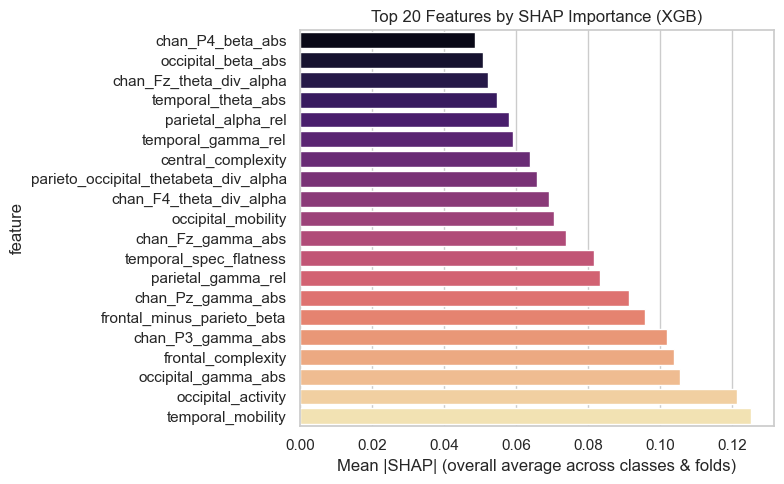

C:\Users\User\AppData\Local\Temp\ipykernel_11176\3492280185.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


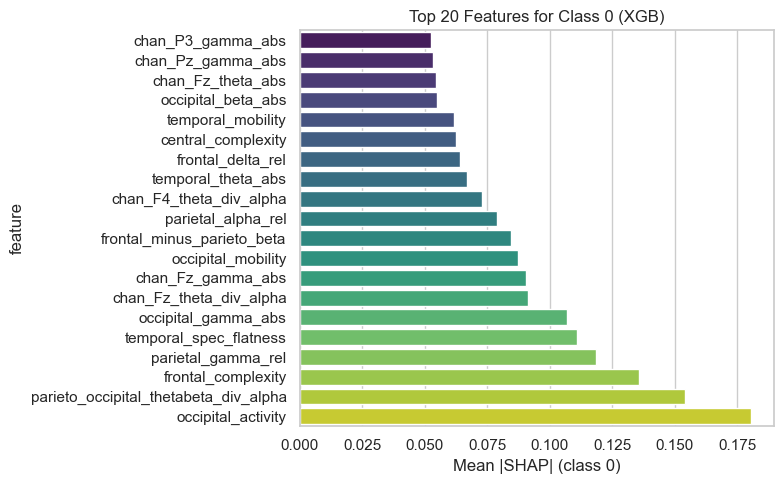

C:\Users\User\AppData\Local\Temp\ipykernel_11176\3492280185.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


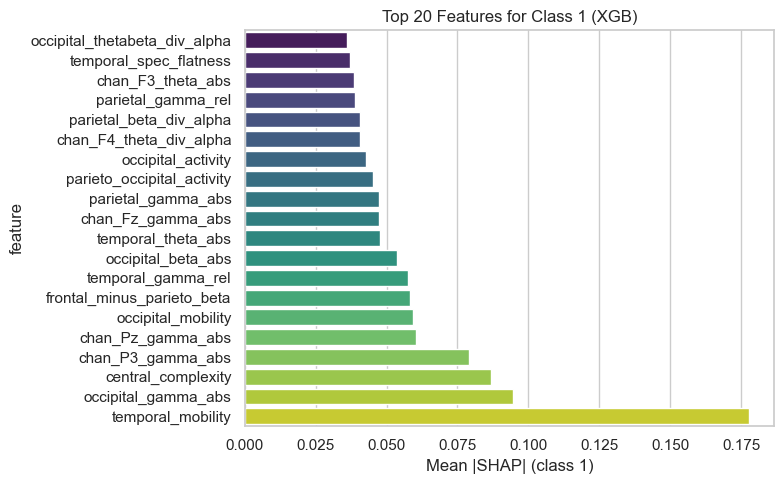

C:\Users\User\AppData\Local\Temp\ipykernel_11176\3492280185.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


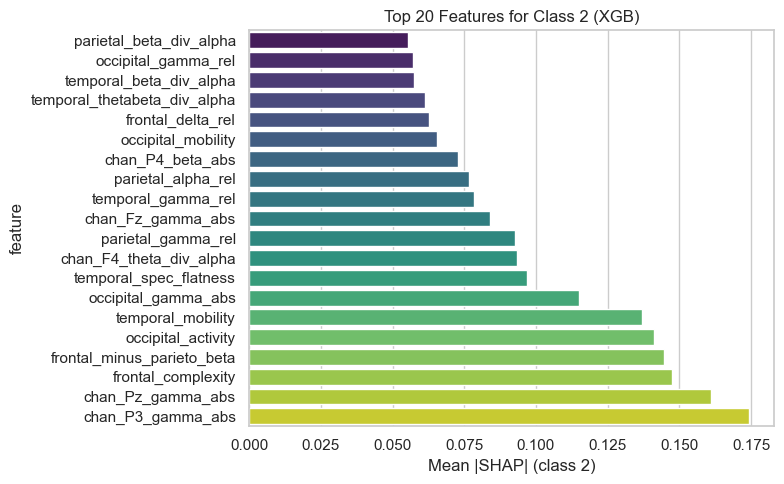

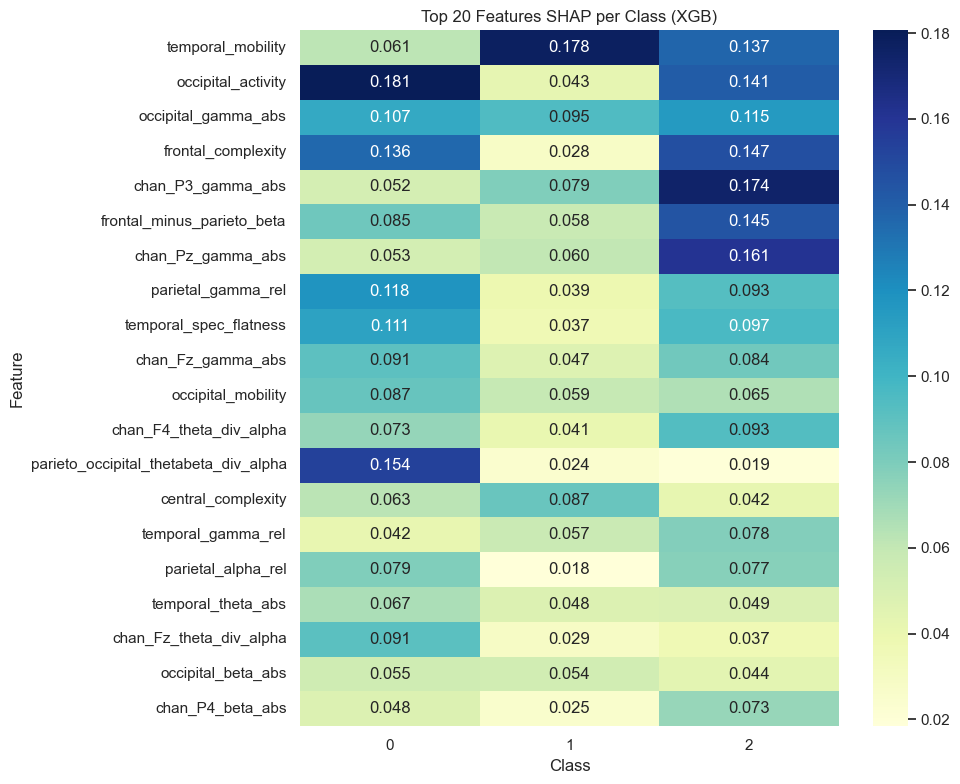

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# --- CONFIG ---
SAVE_DIR = Path(r"C:/Users/User/Jupyter projects/eeg-analysis/cog_bci/features/loso_results/label_3class/2025-12-28_05-59-04/analysis_shap_fixed")
TOP_K = 20  # number of top features to visualize
MODEL_NAME = "XGB"

# --- LOAD DATA ---
agg_df = pd.read_csv(SAVE_DIR / "shap_feature_importance_per_class_by_fold_fixed.csv")
overall_df = pd.read_csv(SAVE_DIR / "shap_feature_importance_overall_fixed.csv")

# --- PLOTTING SETTINGS ---
sns.set(style="whitegrid")
palette = sns.color_palette("viridis", n_colors=agg_df['class'].nunique())

# --- Overall top features ---
top_features = overall_df.head(TOP_K)['feature'].tolist()
plt.figure(figsize=(8, max(4, TOP_K*0.25)))
sns.barplot(
    y=overall_df.head(TOP_K)['feature'][::-1],
    x=overall_df.head(TOP_K)['mean_abs_shap_overall'][::-1],
    palette="magma"
)
plt.xlabel('Mean |SHAP| (overall average across classes & folds)')
plt.title(f"Top {TOP_K} Features by SHAP Importance ({MODEL_NAME})")
plt.tight_layout()
plt.show()

# --- Per-class top features ---
n_classes = agg_df['class'].nunique()
for c in range(n_classes):
    class_df = agg_df[agg_df['class']==c]
    class_top = class_df.sort_values('mean_abs_shap', ascending=False).head(TOP_K)
    plt.figure(figsize=(8, max(4, TOP_K*0.25)))
    sns.barplot(
        y=class_top['feature'][::-1],
        x=class_top['mean_abs_shap'][::-1],
        palette="viridis"
    )
    plt.xlabel(f'Mean |SHAP| (class {c})')
    plt.title(f"Top {TOP_K} Features for Class {c} ({MODEL_NAME})")
    plt.tight_layout()
    plt.show()

# --- Optional: heatmap of features vs classes ---
feature_class_mat = agg_df.pivot(index='feature', columns='class', values='mean_abs_shap').fillna(0)
top_features_heatmap = feature_class_mat.mean(axis=1).sort_values(ascending=False).head(TOP_K).index
plt.figure(figsize=(10, max(4, TOP_K*0.4)))
sns.heatmap(
    feature_class_mat.loc[top_features_heatmap],
    annot=True,
    cmap="YlGnBu",
    fmt=".3f"
)
plt.ylabel("Feature")
plt.xlabel("Class")
plt.title(f"Top {TOP_K} Features SHAP per Class ({MODEL_NAME})")
plt.tight_layout()
plt.show()

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import numpy as np

# ---------------- CONFIG ----------------
SAVE_DIR = Path(r"C:/Users/User/Jupyter projects/eeg-analysis/cog_bci/features/loso_results/label_3class/2025-12-28_05-59-04/analysis_shap_fixed")
TOP_K = 20
MODEL_NAME = "XGB"

OUT_OVERALL = SAVE_DIR / f"shap_top{TOP_K}_overall_{MODEL_NAME}_publication.png"
OUT_PER_CLASS = SAVE_DIR / f"shap_top{TOP_K}_per_class_{MODEL_NAME}_publication.png"
OUT_HEATMAP = SAVE_DIR / f"shap_top{TOP_K}_heatmap_{MODEL_NAME}_publication.png"
OUT_CLASS_SPECIFICITY = SAVE_DIR / f"shap_top{TOP_K}_class_specificity_{MODEL_NAME}_publication.png"
# ----------------------------------------

# Load results
agg_df = pd.read_csv(SAVE_DIR / "shap_feature_importance_per_class_by_fold_fixed.csv")
overall_df = pd.read_csv(SAVE_DIR / "shap_feature_importance_overall_fixed.csv")

# Basic cleaning
agg_df["class"] = agg_df["class"].astype(int)
n_classes = agg_df["class"].nunique()

# Publication-style theme
sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})

def save_fig(fig, path):
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.close(fig)

# ---------------- 1) Overall top features ----------------
top_overall = overall_df.sort_values("mean_abs_shap_overall", ascending=False).head(TOP_K).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, max(4.5, TOP_K * 0.28)))
sns.barplot(
    data=top_overall,
    x="mean_abs_shap_overall",
    y="feature",
    ax=ax,
    color=sns.color_palette("viridis", 8)[4]
)
ax.set_xlabel("Mean absolute SHAP value")
ax.set_ylabel("")
ax.set_title(f"Top {TOP_K} features by overall SHAP importance ({MODEL_NAME})")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
save_fig(fig, OUT_OVERALL)

# ---------------- 2) Per-class top features in one figure ----------------
fig, axes = plt.subplots(1, n_classes, figsize=(5.5 * n_classes, max(4.5, TOP_K * 0.26)), sharex=False)

if n_classes == 1:
    axes = [axes]

for c, ax in enumerate(axes):
    class_df = agg_df[agg_df["class"] == c].copy()
    class_top = class_df.sort_values("mean_abs_shap", ascending=False).head(TOP_K).iloc[::-1]

    sns.barplot(
        data=class_top,
        x="mean_abs_shap",
        y="feature",
        ax=ax,
        color=sns.color_palette("magma", 8)[4]
    )
    ax.set_title(f"Class {c}")
    ax.set_xlabel("Mean absolute SHAP")
    ax.set_ylabel("")  # keep it clean
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(f"Top {TOP_K} features by class-specific SHAP importance ({MODEL_NAME})", y=1.02)
fig.tight_layout()
save_fig(fig, OUT_PER_CLASS)

# ---------------- 3) Heatmap of top overall features across classes ----------------
feature_class_mat = agg_df.pivot_table(
    index="feature",
    columns="class",
    values="mean_abs_shap",
    aggfunc="mean",
    fill_value=0
)

top_features_heatmap = (
    overall_df.sort_values("mean_abs_shap_overall", ascending=False)
    .head(TOP_K)["feature"]
    .tolist()
)

heatmap_df = feature_class_mat.loc[top_features_heatmap].copy()
heatmap_df = heatmap_df.iloc[::-1]  # reverse so strongest feature appears at top

fig, ax = plt.subplots(figsize=(8.5, max(5, TOP_K * 0.30)))
sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    linewidths=0.4,
    linecolor="white",
    cbar_kws={"label": "Mean absolute SHAP"},
    ax=ax
)
ax.set_xlabel("Class")
ax.set_ylabel("")
ax.set_title(f"Top {TOP_K} features: class-wise SHAP importance ({MODEL_NAME})")
save_fig(fig, OUT_HEATMAP)

# ---------------- 4) Optional: class specificity plot ----------------
# This shows how much a feature differs across classes.
# Good for discussion of class-dependent importance.
spec_df = heatmap_df.copy()
spec_df["range"] = spec_df.max(axis=1) - spec_df.min(axis=1)
spec_df = spec_df.sort_values("range", ascending=True).tail(TOP_K).iloc[::-1]
spec_plot = spec_df.drop(columns=["range"])

fig, ax = plt.subplots(figsize=(8.5, max(5, TOP_K * 0.30)))
sns.heatmap(
    spec_plot,
    annot=True,
    fmt=".3f",
    cmap="rocket_r",
    linewidths=0.4,
    linecolor="white",
    cbar_kws={"label": "Mean absolute SHAP"},
    ax=ax
)
ax.set_xlabel("Class")
ax.set_ylabel("")
ax.set_title(f"Most class-specific features by SHAP ({MODEL_NAME})")
save_fig(fig, OUT_CLASS_SPECIFICITY)

print("Saved figures to:", SAVE_DIR)
print("Created:")
print(" -", OUT_OVERALL.name)
print(" -", OUT_PER_CLASS.name)
print(" -", OUT_HEATMAP.name)
print(" -", OUT_CLASS_SPECIFICITY.name)

Saved figures to: C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\loso_results\label_3class\2025-12-28_05-59-04\analysis_shap_fixed
Created:
 - shap_top20_overall_XGB_publication.png
 - shap_top20_per_class_XGB_publication.png
 - shap_top20_heatmap_XGB_publication.png
 - shap_top20_class_specificity_XGB_publication.png


In [2]:
import json
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import shap
from sklearn.pipeline import Pipeline

# ---------------- CONFIG ----------------
OUT_DIR = Path(r"C:/Users/User/Jupyter projects/eeg-analysis/cog_bci/features/loso_results/label_3class/2025-12-28_05-59-04")
CSV_PATH = Path(r"C:/Users/User/Jupyter projects/eeg-analysis/cog_bci/features/features_final_prepared.csv")
MODEL_NAME = "XGB"
SAVE_DIR = OUT_DIR / "analysis_shap_fixed"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

ID_COLS = [
    "subject", "subject_num", "session", "session_num", "task", "epoch_idx", "source_file",
    "label_3class", "label_binary", "rsme_score", "pc_dist", "is_outlier"
]

CLASS_COL = "label_3class"
RANDOM_STATE = 42
MAX_DISPLAY = 12  # number of features shown in each waterfall
# ----------------------------------------


def get_pipeline_and_parts(mdl):
    """Return (transformer, classifier) from a loaded joblib model or search object."""
    if hasattr(mdl, "best_estimator_"):
        pipe = mdl.best_estimator_
    else:
        pipe = mdl

    if isinstance(pipe, Pipeline):
        steps = list(pipe.named_steps.items())
        if len(steps) == 0:
            return None, pipe
        if len(steps) > 1:
            transformer = Pipeline(steps[:-1])
        else:
            transformer = None
        classifier = steps[-1][1]
        return transformer, classifier

    return None, pipe


def find_selected_feature_names(transformer, feat_cols):
    """Try to recover the selected feature names after feature selection."""
    if transformer is None:
        return feat_cols

    if hasattr(transformer, "named_steps"):
        for _, step in transformer.named_steps.items():
            if hasattr(step, "get_support"):
                try:
                    mask = step.get_support()
                    if len(mask) == len(feat_cols):
                        return [feat_cols[i] for i, m in enumerate(mask) if m]
                except Exception:
                    pass
    else:
        if hasattr(transformer, "get_support"):
            try:
                mask = transformer.get_support()
                if len(mask) == len(feat_cols):
                    return [feat_cols[i] for i, m in enumerate(mask) if m]
            except Exception:
                pass

    return feat_cols


def transform_with_pipeline(transformer, X_df):
    """Transform dataframe using the saved preprocessing pipeline."""
    if transformer is None:
        return X_df.values
    try:
        return transformer.transform(X_df.values)
    except Exception:
        return transformer.transform(X_df)


def patch_xgb_base_score(booster):
    """
    Work around XGBoost multiclass base_score config issue that can break SHAP.
    """
    try:
        cfg = json.loads(booster.save_config())
        base = cfg["learner"]["learner_model_param"].get("base_score", None)
        if isinstance(base, str) and "[" in base:
            cfg["learner"]["learner_model_param"]["base_score"] = "0.5"
            booster.load_config(json.dumps(cfg))
    except Exception:
        pass


def compute_signed_shap_for_one_sample(clf, X_one):
    """
    Return raw signed SHAP values for a single sample.
    Output format is normalized to:
      - if multiclass: (n_classes, n_features)
      - if single output: (1, n_features)
    """
    if not hasattr(clf, "get_booster"):
        raise ValueError("Classifier does not expose get_booster(); this is not an XGBoost model.")

    booster = clf.get_booster()
    patch_xgb_base_score(booster)

    explainer = shap.TreeExplainer(
        booster,
        feature_perturbation="tree_path_dependent",
        model_output="raw"
    )

    raw = explainer.shap_values(X_one)

    # Normalize to class-first structure
    if isinstance(raw, list):
        # list of arrays, one per class -> (n_classes, n_features)
        arr = np.vstack([np.asarray(r).reshape(-1) for r in raw])
        return arr, explainer.expected_value

    arr = np.asarray(raw)

    # Common shapes for a single row:
    # (1, n_features)
    if arr.ndim == 2 and arr.shape[0] == 1:
        return arr, explainer.expected_value

    # (1, n_features, n_classes) -> (n_classes, n_features)
    if arr.ndim == 3 and arr.shape[0] == 1:
        arr = np.transpose(arr[0], (1, 0))  # (n_classes, n_features) if shape was (1, n_features, n_classes)
        return arr, explainer.expected_value

    # (n_classes, 1, n_features) -> (n_classes, n_features)
    if arr.ndim == 3 and arr.shape[1] == 1:
        arr = arr[:, 0, :]
        return arr, explainer.expected_value

    # Fallback: flatten single-output row
    if arr.ndim == 1:
        return arr.reshape(1, -1), explainer.expected_value

    raise ValueError(f"Unhandled SHAP output shape for one sample: {arr.shape}")


def save_waterfall_plot(feature_names, x_one, shap_vec, base_value, out_path, title, max_display=12):
    """
    Save a SHAP waterfall plot for one sample.
    """
    explanation = shap.Explanation(
        values=shap_vec,
        base_values=base_value,
        data=np.asarray(x_one).reshape(-1),
        feature_names=feature_names
    )

    plt.figure(figsize=(10, 6))
    shap.plots.waterfall(explanation, max_display=max_display, show=False)
    plt.title(title)
    plt.tight_layout()
    plt.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.close()


# ---------------- LOAD DATA ----------------
df = pd.read_csv(CSV_PATH)
if "subject_num" not in df.columns:
    raise KeyError("subject_num not found in the feature CSV.")

feat_cols = [c for c in df.columns if c not in ID_COLS and c not in ("label_3class", "label_binary", "rsme_score")]
fold_json_files = sorted(glob.glob(str(OUT_DIR / "fold_*_summary.json")))

if len(fold_json_files) == 0:
    raise FileNotFoundError(f"No fold summary JSONs found in {OUT_DIR}")

# ---------------- FIND REPRESENTATIVE SAMPLE PER CLASS ----------------
# We choose, for each true class, the correctly classified sample with the highest predicted probability.
best_sample = {
    0: None,
    1: None,
    2: None
}

for jf in fold_json_files:
    j = json.load(open(jf, "r"))
    test_subject = j.get("test_subject", None)
    if test_subject is None:
        basename = Path(jf).stem
        try:
            test_subject = int(basename.split("_")[1])
        except Exception:
            continue
    test_subject = int(test_subject)

    model_candidates = glob.glob(str(OUT_DIR / f"fold_{test_subject}*{MODEL_NAME}*.joblib"))
    if len(model_candidates) == 0:
        continue

    model_path = Path(model_candidates[0])
    mdl = joblib.load(model_path)
    transformer, clf = get_pipeline_and_parts(mdl)

    test_mask = (pd.to_numeric(df["subject_num"], errors="coerce") == test_subject)
    X_test_df = df.loc[test_mask, feat_cols].copy()
    y_true = pd.to_numeric(df.loc[test_mask, CLASS_COL], errors="coerce").astype(int).values

    if X_test_df.shape[0] == 0:
        continue

    X_test_trans = transform_with_pipeline(transformer, X_test_df)

    try:
        proba = clf.predict_proba(X_test_trans)
        y_pred = np.argmax(proba, axis=1)
    except Exception:
        # If predict_proba is unavailable for some reason, skip this fold
        continue

    for c in [0, 1, 2]:
        idxs = np.where((y_true == c) & (y_pred == c))[0]
        if len(idxs) == 0:
            continue

        # choose the correctly classified sample with the highest probability for its true class
        candidate_probs = proba[idxs, c]
        best_local_idx = idxs[np.argmax(candidate_probs)]
        best_local_prob = float(proba[best_local_idx, c])

        if (best_sample[c] is None) or (best_local_prob > best_sample[c]["prob_true"]):
            best_sample[c] = {
                "fold": test_subject,
                "model_path": str(model_path),
                "sample_idx": int(best_local_idx),
                "prob_true": best_local_prob,
                "y_true": int(y_true[best_local_idx]),
                "y_pred": int(y_pred[best_local_idx]),
                "X_row": X_test_df.iloc[best_local_idx:best_local_idx + 1].copy(),
                "transformer": transformer,
                "clf": clf,
            }

# ---------------- CREATE WATERFALL PLOTS ----------------
summary_rows = []

for c in [0, 1, 2]:
    info = best_sample[c]
    if info is None:
        print(f"Could not find a correctly classified representative sample for class {c}.")
        continue

    transformer = info["transformer"]
    clf = info["clf"]
    X_row_df = info["X_row"]
    X_row_trans = transform_with_pipeline(transformer, X_row_df)

    feature_names = find_selected_feature_names(transformer, feat_cols)

    # SHAP for one sample
    shap_arr, expected_value = compute_signed_shap_for_one_sample(clf, X_row_trans)

    # Select class-specific SHAP vector
    # For multiclass, shap_arr is (n_classes, n_features)
    # For binary/single output fallback, shap_arr may be (1, n_features)
    if shap_arr.shape[0] > 1:
        shap_vec = shap_arr[c]
        if isinstance(expected_value, (list, np.ndarray)) and len(np.asarray(expected_value)) > c:
            base_value = np.asarray(expected_value)[c]
        else:
            base_value = expected_value
    else:
        shap_vec = shap_arr[0]
        base_value = expected_value if not isinstance(expected_value, (list, np.ndarray)) else np.asarray(expected_value)[0]

    # Save waterfall
    out_path = SAVE_DIR / f"waterfall_class{c}_fold{info['fold']}_sample{info['sample_idx']}_{MODEL_NAME}.png"
    title = (
        f"SHAP waterfall for class {c} | fold {info['fold']} | "
        f"true={info['y_true']} pred={info['y_pred']} p(true)={info['prob_true']:.3f}"
    )
    save_waterfall_plot(
        feature_names=feature_names,
        x_one=X_row_trans,
        shap_vec=shap_vec,
        base_value=base_value,
        out_path=out_path,
        title=title,
        max_display=MAX_DISPLAY
    )

    summary_rows.append({
        "class": c,
        "fold": info["fold"],
        "sample_idx": info["sample_idx"],
        "prob_true": info["prob_true"],
        "y_true": info["y_true"],
        "y_pred": info["y_pred"],
        "figure_path": str(out_path)
    })

# ---------------- SAVE SUMMARY ----------------
summary_df = pd.DataFrame(summary_rows)
summary_csv = SAVE_DIR / f"waterfall_selected_samples_{MODEL_NAME}.csv"
summary_df.to_csv(summary_csv, index=False)

print("Saved waterfall plots and summary to:", SAVE_DIR)
print(summary_df.to_string(index=False))

C:\Users\User\anaconda3\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator SelectKBest from version 1.6.1 when using version 1.7.2. This might lead to breaking code o

Saved waterfall plots and summary to: C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\loso_results\label_3class\2025-12-28_05-59-04\analysis_shap_fixed
 class  fold  sample_idx  prob_true  y_true  y_pred                                                                                                                                                              figure_path
     0    21         740   0.997508       0       0 C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\loso_results\label_3class\2025-12-28_05-59-04\analysis_shap_fixed\waterfall_class0_fold21_sample740_XGB.png
     1     2         929   0.996669       1       1  C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\loso_results\label_3class\2025-12-28_05-59-04\analysis_shap_fixed\waterfall_class1_fold2_sample929_XGB.png
     2    25          48   0.999062       2       2  C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\loso_results\label_3class\2025-12-28_05-59-04\analysis_sha